# 10 · Prediction Maps: Classifier-only vs HMM/Viterbi (report §6)
**Owner:** Patil · **Code:** `viz/folium_maps.py` · **Partition:** student_test (10 trips) · **Inputs:** `results/preds/hmm_<trip>.parquet` (from `python -m evaluation.hmm_eval`), `results/hmm_comparison.csv`

Each map has toggleable layers (layer control, top right) and a legend (bottom left):
- **Raw GPS** (blue dots)
- **Road network** (grey, clipped to the trip area)
- **Reference route** (green, thick)
- **Classifier-only prediction** (orange): tuned LightGBM argmax per point
- **HMM/Viterbi prediction** (red)
- **GPS points where the HMM is wrong** (black, off by default)

The reference route is used only to visualise and score student_test results offline. The predictor never reads it.

,variant,n_obs,top1,route_continuity,breaks,route_arc_precision,route_arc_recall
0,classifier_only,19160,0.8847,0.9543,0,0.8953,0.8958
1,hmm_geometry_only(w=0),19160,0.9084,0.9776,5,0.9503,0.9096
2,hmm_tuned,19160,0.9301,0.9790,5,0.9651,0.9114


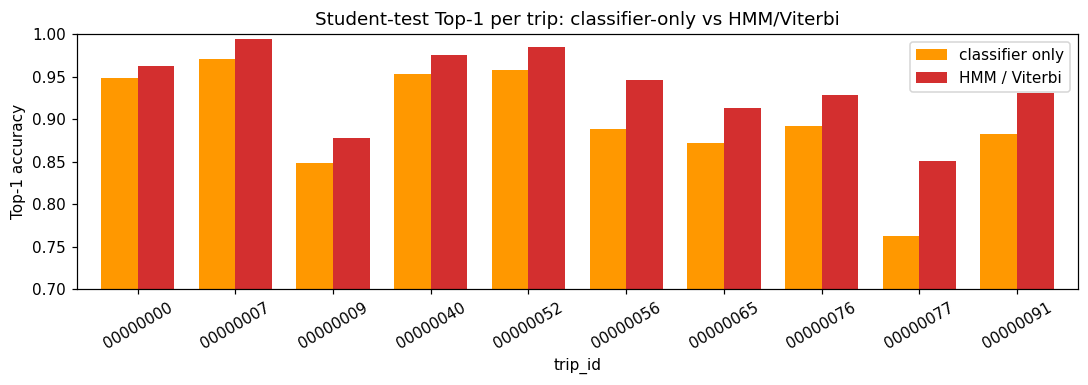

HMM improved 10 of 10 trips; mean gain 0.0386


In [1]:
import os, sys
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
from viz.folium_maps import make_prediction_map
hc = pd.read_csv("results/hmm_comparison.csv", dtype={"trip_id": str})
display(hc[hc.trip_id == "ALL"][["variant", "n_obs", "top1", "route_continuity", "breaks", "route_arc_precision", "route_arc_recall"]].round(4))
per = hc[hc.trip_id != "ALL"].pivot(index="trip_id", columns="variant", values="top1")[["classifier_only", "hmm_tuned"]]
ax = per.plot.bar(figsize=(10, 3.6), color=["#ff9800", "#d32f2f"], width=0.75)
ax.set_ylim(0.7, 1.0); ax.set_ylabel("Top-1 accuracy"); ax.set_title("Student-test Top-1 per trip: classifier-only vs HMM/Viterbi")
ax.legend(["classifier only", "HMM / Viterbi"]); plt.xticks(rotation=30); plt.tight_layout()
plt.savefig("results/plots/hmm_vs_classifier_per_trip.png"); plt.show()
print("HMM improved", int((per.hmm_tuned > per.classifier_only).sum()), "of", len(per), "trips; mean gain",
      round((per.hmm_tuned - per.classifier_only).mean(), 4))

## Map 1: trip 00000007 (best trip: classifier 0.970 → HMM 0.994)
Compare the orange (classifier-only) and red (HMM) layers against the green reference. Toggle layers on and off to see where the per-point classifier picks arcs that the connected HMM route does not use.

In [2]:
m, path, s = make_prediction_map("00000007"); print(path, s); m

results\maps\prediction_00000007.html {'trip_id': '00000007', 'n_points': 1354, 'clf_top1': 0.9704579025110783, 'hmm_top1': 0.9940915805022157, 'hmm_wrong': 8}


## Map 2: trip 00000077 (hardest trip, biggest gain: 0.763 → 0.850)
The hardest student_test trip for the classifier. Switch on the black "HMM wrong" layer to inspect where the remaining 585 HMM errors are located.

In [3]:
m, path, s = make_prediction_map("00000077"); print(path, s); m

results\maps\prediction_00000077.html {'trip_id': '00000077', 'n_points': 3911, 'clf_top1': 0.7627205318332907, 'hmm_top1': 0.8504218869854258, 'hmm_wrong': 585}


## Map 3: trip 00000056 (largest trip, 3,958 points: 0.889 → 0.946)
Saved to `results/maps/prediction_00000056.html` (open in a browser; not rendered inline to keep this notebook small).

In [4]:
_, path, s = make_prediction_map("00000056"); print(path, s)

results\maps\prediction_00000056.html {'trip_id': '00000056', 'n_points': 3958, 'clf_top1': 0.8888327438100051, 'hmm_top1': 0.9464375947448206, 'hmm_wrong': 212}
